#### Step 1: Import Necessary Libraries

In [4]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split

from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import BaggingClassifier

from sklearn.metrics import accuracy_score
from sklearn.metrics import confusion_matrix
from sklearn.metrics import classification_report

#### Step 2: Data Collection

In [5]:
titanic_data = pd.read_csv("titanic.csv")
titanic_data

,Survived,Pclass,Name,Sex,Age,Siblings/Spouses Aboard,Parents/Children Aboard,Fare
0,0,3,Mr. Owen Harris Braund,male,22.0,1,0,7.2500
1,1,1,Mrs. John Bradley (Florence Briggs Thayer) Cum...,female,38.0,1,0,71.2833
2,1,3,Miss. Laina Heikkinen,female,26.0,0,0,7.9250
3,1,1,Mrs. Jacques Heath (Lily May Peel) Futrelle,female,35.0,1,0,53.1000
4,0,3,Mr. William Henry Allen,male,35.0,0,0,8.0500
...,...,...,...,...,...,...,...,...
882,0,2,Rev. Juozas Montvila,male,27.0,0,0,13.0000
883,1,1,Miss. Margaret Edith Graham,female,19.0,0,0,30.0000
884,0,3,Miss. Catherine Helen Johnston,female,7.0,1,2,23.4500
885,1,1,Mr. Karl Howell Behr,male,26.0,0,0,30.0000


#### Step 3: Data Understanding

In [6]:
titanic_data.shape

(887, 8)

In [7]:
titanic_data.isna().sum()

Survived                   0
Pclass                     0
Name                       0
Sex                        0
Age                        0
Siblings/Spouses Aboard    0
Parents/Children Aboard    0
Fare                       0
dtype: int64

In [8]:
titanic_data.duplicated().sum()

0

In [9]:
titanic_data.describe()

,Survived,Pclass,Age,Siblings/Spouses Aboard,Parents/Children Aboard,Fare
count,887.000000,887.000000,887.000000,887.000000,887.000000,887.00000
mean,0.385569,2.305524,29.471443,0.525366,0.383315,32.30542
std,0.487004,0.836662,14.121908,1.104669,0.807466,49.78204
min,0.000000,1.000000,0.420000,0.000000,0.000000,0.00000
25%,0.000000,2.000000,20.250000,0.000000,0.000000,7.92500
50%,0.000000,3.000000,28.000000,0.000000,0.000000,14.45420
75%,1.000000,3.000000,38.000000,1.000000,0.000000,31.13750
max,1.000000,3.000000,80.000000,8.000000,6.000000,512.32920


#### Step 4: Data Preparation

In [10]:
titanic_data.drop("Name", axis=1, inplace=True)

titanic_data.head()

,Survived,Pclass,Sex,Age,Siblings/Spouses Aboard,Parents/Children Aboard,Fare
0,0,3,male,22.0,1,0,7.2500
1,1,1,female,38.0,1,0,71.2833
2,1,3,female,26.0,0,0,7.9250
3,1,1,female,35.0,1,0,53.1000
4,0,3,male,35.0,0,0,8.0500


In [11]:
titanic_data["Sex"] = titanic_data["Sex"].map({
    "male": 0,
    "female": 1})

In [12]:
titanic_data.head()

,Survived,Pclass,Sex,Age,Siblings/Spouses Aboard,Parents/Children Aboard,Fare
0,0,3,0,22.0,1,0,7.2500
1,1,1,1,38.0,1,0,71.2833
2,1,3,1,26.0,0,0,7.9250
3,1,1,1,35.0,1,0,53.1000
4,0,3,0,35.0,0,0,8.0500


In [13]:
titanic_data.isnull().sum()

Survived                   0
Pclass                     0
Sex                        0
Age                        0
Siblings/Spouses Aboard    0
Parents/Children Aboard    0
Fare                       0
dtype: int64

In [14]:
X = titanic_data.drop("Survived", axis=1)

y = titanic_data["Survived"]

#### Step 5: Train-Test Split

In [15]:
X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.2,random_state=42,stratify=y)

#### Step 6: Model Building

In [16]:
decision_tree_model = DecisionTreeClassifier(random_state=42)

In [22]:
bagging_model = BaggingClassifier(
    base_estimator=decision_tree_model,
    n_estimators=100,
    max_samples=0.8,
    bootstrap=True,
    random_state=42)

#### Step 7: Model Training

In [23]:
bagging_model.fit(X_train, y_train)

BaggingClassifier(base_estimator=DecisionTreeClassifier(random_state=42),
                  max_samples=0.8, n_estimators=100, random_state=42)

#### Step 8: Model Testing

In [24]:
predicted_survival = bagging_model.predict(X_test)

predicted_survival

array([0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 1, 1, 1, 0, 1, 1, 0, 1, 0, 0, 0, 1,
       0, 1, 1, 0, 1, 1, 0, 0, 1, 0, 0, 1, 1, 0, 1, 1, 0, 0, 0, 1, 0, 0,
       0, 1, 0, 0, 0, 0, 0, 1, 0, 1, 1, 1, 0, 0, 1, 1, 0, 1, 1, 1, 0, 1,
       0, 0, 1, 1, 0, 1, 0, 0, 0, 1, 1, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       1, 1, 0, 1, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 1, 1, 0, 0, 0, 0, 0,
       1, 0, 1, 0, 0, 1, 1, 0, 0, 1, 1, 0, 1, 0, 1, 0, 1, 0, 0, 0, 0, 1,
       1, 0, 0, 0, 0, 1, 0, 0, 1, 0, 1, 1, 0, 1, 1, 0, 0, 0, 1, 0, 0, 0,
       1, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 1, 1, 0, 0, 0, 1, 1,
       0, 1], dtype=int64)

In [25]:
prediction_results = pd.DataFrame({
    "Actual Survival": y_test.values,
    "Predicted Survival": predicted_survival
})

prediction_results.head(10)

,Actual Survival,Predicted Survival
0,0,0
1,0,0
2,0,1
3,0,0
4,0,0
5,0,0
6,0,0
7,0,0
8,1,0
9,1,0


#### Step 9: Model Evaluation

In [27]:
model_accuracy = accuracy_score(
    y_test,
    predicted_survival
)

print("Bagging Model Accuracy:", model_accuracy)

print("Accuracy Percentage:", model_accuracy * 100)

Bagging Model Accuracy: 0.7865168539325843
Accuracy Percentage: 78.65168539325843


[[91 18]
 [20 49]]


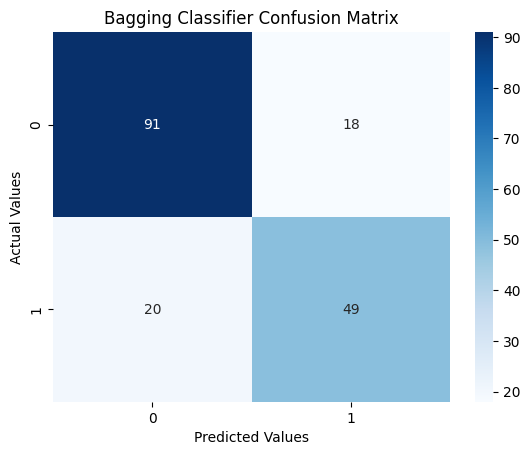

In [28]:
confusion_matrix_result = confusion_matrix(
    y_test,
    predicted_survival
)

print(confusion_matrix_result)

sns.heatmap(
    confusion_matrix_result,
    annot=True,
    fmt="d",
    cmap="Blues"
)

plt.title("Bagging Classifier Confusion Matrix")
plt.xlabel("Predicted Values")
plt.ylabel("Actual Values")
plt.show()

In [29]:
print(classification_report(
    y_test,
    predicted_survival
))

              precision    recall  f1-score   support

           0       0.82      0.83      0.83       109
           1       0.73      0.71      0.72        69

    accuracy                           0.79       178
   macro avg       0.78      0.77      0.77       178
weighted avg       0.79      0.79      0.79       178



In [31]:
print("========== BAGGING CLASSIFIER RESULT ==========")

print("Total Training Records:", len(X_train))

print("Total Testing Records:", len(X_test))

print("Number of Decision Trees:", 100)

print("Model Accuracy:", round(model_accuracy * 100, 2), "%")

print("================================================")

========== BAGGING CLASSIFIER RESULT ==========
Total Training Records: 709
Total Testing Records: 178
Number of Decision Trees: 100
Model Accuracy: 78.65 %
